In [1]:
import sys, scanpy as sc
print(sys.version)
print(sc.__version__)

3.12.15 (main, Oct  9 2026, 15:21:55) [MSC v.1944 64 bit (AMD64)]
1.12.4


C:\Users\hp\AppData\Local\Temp\ipykernel_23996\3898917610.py:3: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('scanpy')` instead
  print(sc.__version__)


In [2]:
from pathlib import Path
import os

print(os.getcwd())
DATA = Path("../data")
f_tpm  = DATA / "GSE120575_Sade_Feldman_melanoma_single_cells_TPM_GEO.txt.gz"
f_meta = DATA / "GSE120575_patient_ID_single_cells.txt.gz"
print(f_tpm.exists(), f_meta.exists())

f:\melanoma\melanoma-scrna-analysis\notebooks
True True


In [3]:
import gzip
with gzip.open(f_meta, "rt") as fh:
    for i, line in enumerate(fh):
        print(i, line[:150].rstrip())
        if i >= 30: break

0 # High-throughput sequencing metadata template (version 2.1).
1 # All fields in this template must be completed.
2 # Templates containing example data are found in the METADATA EXAMPLES spreadsheet tabs at the foot of this page.
3 # Field names (in blue on this page) should not be edited. Hover over cells containing field names to view field content guidelines.
4 "# Human data. If there are patient privacy concerns regarding making data fully public through GEO, please submit to NCBI's dbGaP (http://www.ncbi.nl
5 
6 SERIES
7 # This section describes the overall experiment.
8 title	Defining T cell states associated with response to checkpoint immunotherapy in melanoma
9 summary	"we profiled 16,291 immune cells from 48 tumor samples of melanoma patients treated with checkpoint inhibitors, using single-cell transcriptom
10 overall design	"Tumors were disaggregated, sorted into CD45+ single cells, and profiled by Smart-seq2"
11 contributor	Moshe Sade-Feldman
12 contributor	Keren Yizhak
1

In [4]:
with gzip.open(f_tpm, "rt") as fh:
    for i, line in enumerate(fh):
        print(i, len(line.split("\t")), line[:300].rstrip())
        if i >= 2: break

0 16292 	A10_P3_M11	A11_P1_M11	A11_P3_M11	A11_P4_M11	A12_P3_M11	A12_P6_M11	A2_P1_M11	A2_P4_M11	A3_P1_M11	A3_P3_M11	A4_P3_M11	A4_P4_M11	A4_P6_M11	A5_P4_M11	A5_P5_M11	A6_P1_M11	A6_P4_M11	A6_P6_M11	A7_P2_M11	A7_P6_M11	A8_P1_M11	A8_P6_M11	A9_P1_M11	A9_P4_M11	B10_P1_M11	B10_P3_M11	B10_P4_M11	B10_P6_M11	B11_P6_M1
1 16292 	Pre_P1	Pre_P1	Pre_P1	Pre_P1	Pre_P1	Pre_P1	Pre_P1	Pre_P1	Pre_P1	Pre_P1	Pre_P1	Pre_P1	Pre_P1	Pre_P1	Pre_P1	Pre_P1	Pre_P1	Pre_P1	Pre_P1	Pre_P1	Pre_P1	Pre_P1	Pre_P1	Pre_P1	Pre_P1	Pre_P1	Pre_P1	Pre_P1	Pre_P1	Pre_P1	Pre_P1	Pre_P1	Pre_P1	Pre_P1	Pre_P1	Pre_P1	Pre_P1	Pre_P1	Pre_P1	Pre_P1	Pre_P1	Pre_P1	Pre_P
2 16293 TSPAN6	0.00	0.00	0.00	0.00	0.00	0.00	0.00	0.00	0.00	0.00	0.00	0.00	0.00	0.00	0.00	0.00	0.00	0.00	0.00	0.00	0.00	0.00	0.00	0.00	0.00	0.00	0.00	0.00	0.00	0.00	0.00	0.00	0.00	0.00	0.00	0.00	0.00	0.00	0.00	0.00	0.00	0.00	0.00	0.00	0.00	0.00	0.00	0.00	0.00	0.00	0.00	0.00	0.00	0.00	0.00	0.00	0.00	0.00	0.0


In [5]:
with gzip.open(f_tpm, "rt") as fh:
    for i, line in enumerate(fh):
        parts = line.rstrip("\n").split("\t")
        print(i, "تعداد فیلد:", len(parts))
        print("   اولین فیلدها:", [repr(p) for p in parts[:3]])
        print("   آخرین فیلدها:", [repr(p) for p in parts[-3:]])
        if i >= 4:
            break

0 تعداد فیلد: 16292
   اولین فیلدها: ["''", "'A10_P3_M11'", "'A11_P1_M11'"]
   آخرین فیلدها: ["'H7_P5_M67_L001_T_enriched'", "'H8_P5_M67_L001_T_enriched'", "'H9_P5_M67_L001_T_enriched'"]
1 تعداد فیلد: 16292
   اولین فیلدها: ["''", "'Pre_P1'", "'Pre_P1'"]
   آخرین فیلدها: ["'Post_P6_T_enriched'", "'Post_P6_T_enriched'", "'Post_P6_T_enriched'"]
2 تعداد فیلد: 16293
   اولین فیلدها: ["'TSPAN6'", "'0.00'", "'0.00'"]
   آخرین فیلدها: ["'0.00'", "'0.00'", "''"]
3 تعداد فیلد: 16293
   اولین فیلدها: ["'TNMD'", "'0.00'", "'0.00'"]
   آخرین فیلدها: ["'0.00'", "'0.00'", "''"]
4 تعداد فیلد: 16293
   اولین فیلدها: ["'DPM1'", "'0.00'", "'9.24'"]
   آخرین فیلدها: ["'0.00'", "'0.00'", "''"]


In [6]:
import pandas as pd

meta = pd.read_csv(f_meta, sep="\t", skiprows=19, nrows=16291, encoding="latin-1")
meta = meta.loc[:, ~meta.columns.str.startswith("Unnamed")]
cols = meta.columns.tolist()
print(cols)

meta = meta.rename(columns={
    cols[1]: "cell_id",
    cols[4]: "sample",
    cols[5]: "response",
    cols[6]: "therapy",
})

for c in ["cell_id", "sample", "response", "therapy"]:
    meta[c] = meta[c].str.strip()

meta = meta.set_index("cell_id")
meta["timepoint"]  = meta["sample"].str.split("_").str[0]
meta["patient"]    = meta["sample"].str.split("_").str[1]
meta["T_enriched"] = meta.index.str.contains("T_enriched")

print(meta.shape)
print(meta.index.is_unique)
print(meta["sample"].nunique(), meta["patient"].nunique())
print(meta["response"].value_counts())
print(meta["therapy"].value_counts())
print(meta.groupby("patient")["response"].nunique().max())
print(meta["T_enriched"].value_counts())
print(meta[["sample", "response", "therapy"]].tail(3))


['Sample name', 'title', 'source name', 'organism', 'characteristics: patinet ID (Pre=baseline; Post= on treatment)', 'characteristics: response', 'characteristics: therapy', 'molecule', 'description', 'processed data file ', 'raw file']
(16291, 13)
True
48 32
response
Non-responder    10727
Responder         5564
Name: count, dtype: int64
therapy
anti-PD1          11653
anti-CTLA4+PD1     4121
anti-CTLA4          517
Name: count, dtype: int64
2
T_enriched
False    15418
True       873
Name: count, dtype: int64
                            sample       response   therapy
cell_id                                                    
H7_P5_M67_L001_T_enriched  Post_P6  Non-responder  anti-PD1
H8_P5_M67_L001_T_enriched  Post_P6  Non-responder  anti-PD1
H9_P5_M67_L001_T_enriched  Post_P6  Non-responder  anti-PD1


In [7]:
meta = meta.loc[:, ~meta.columns.str.startswith("Unnamed")]

meta["T_enriched"] = meta.index.str.contains("T_enriched")
print(meta["T_enriched"].value_counts())

ct = pd.crosstab(meta["sample"], meta["T_enriched"])
print(ct[ct.get(True, 0) > 0])

n_lab = meta.groupby("patient")["response"].nunique()
mixed = n_lab[n_lab > 1].index.tolist()
print("بیماران با دو برچسب:", mixed)
print(meta[meta["patient"].isin(mixed)]
      .groupby(["patient", "sample", "response", "therapy"]).size())

T_enriched
False    15418
True       873
Name: count, dtype: int64
T_enriched  False  True 
sample                  
Post_P10      308     88
Post_P13      265    184
Post_P16      369     94
Post_P2       301     79
Post_P4       421    254
Post_P6       308     92
Post_P8       327     82
بیماران با دو برچسب: ['P1', 'P28', 'P4', 'P5']
patient  sample      response       therapy       
P1       Post_P1     Responder      anti-PD1          291
         Post_P1_2   Non-responder  anti-PD1          353
         Pre_P1      Responder      anti-CTLA4        229
P28      Post_P28    Non-responder  anti-CTLA4+PD1    369
         Post_P28_2  Non-responder  anti-CTLA4+PD1    372
         Pre_P28     Responder      anti-CTLA4+PD1    337
P4       Post_P4     Responder      anti-CTLA4+PD1    675
         Pre_P4      Non-responder  anti-CTLA4+PD1    311
P5       Post_P5     Non-responder  anti-PD1          292
         Post_P5_2   Responder      anti-PD1          336
dtype: int64


In [8]:
extra = ["molecule", "description", "processed data file ", "raw file"]
print(meta[extra].nunique())
print(meta[extra].drop_duplicates().head())

molecule                0
description             0
processed data file     0
raw file                0
dtype: int64
            molecule  description  processed data file   raw file
cell_id                                                          
A10_P3_M11       NaN          NaN                   NaN       NaN


In [9]:
print(meta[["Sample name", "source name", "organism"]].nunique())

keep = ["sample", "response", "therapy", "timepoint", "patient", "T_enriched"]
meta = meta[keep].copy()

print(meta.shape)
print(meta.head(3))

Sample name    16291
source name        1
organism           1
dtype: int64
(16291, 6)
            sample   response     therapy timepoint patient  T_enriched
cell_id                                                                
A10_P3_M11  Pre_P1  Responder  anti-CTLA4       Pre      P1       False
A11_P1_M11  Pre_P1  Responder  anti-CTLA4       Pre      P1       False
A11_P3_M11  Pre_P1  Responder  anti-CTLA4       Pre      P1       False


In [10]:
import gzip
import numpy as np
import pandas as pd
import scipy.sparse as sp
import anndata as ad

# 1) Read the two header lines (cell IDs and per-cell sample labels)
with gzip.open(f_tpm, "rt") as fh:
    cell_ids      = fh.readline().rstrip("\n").split("\t")[1:]   # [1:] skips the empty first field
    sample_labels = fh.readline().rstrip("\n").split("\t")[1:]
n_cells = len(cell_ids)
print(n_cells, len(sample_labels))

# 2) Read the gene rows in chunks and store each chunk as a sparse matrix
blocks, genes = [], []
reader = pd.read_csv(f_tpm, sep="\t", skiprows=2, header=None, index_col=0,
                     usecols=range(n_cells + 1),   # gene name + cell columns; drops the trailing empty field
                     chunksize=2000)               # 2000 genes at a time to avoid running out of RAM
for ch in reader:
    genes.extend(ch.index.tolist())
    blocks.append(sp.csr_matrix(ch.to_numpy(dtype="float32")))
    if len(blocks) % 5 == 0:
        print(len(genes), "genes read")

# 3) Build the AnnData object (rows = cells, columns = genes)
X = sp.vstack(blocks).T.tocsr()   # stack chunks (genes x cells), then transpose to cells x genes
adata = ad.AnnData(
    X,
    obs=pd.DataFrame({"matrix_sample": sample_labels}, index=cell_ids),   # keep the matrix sample label for a later consistency check
    var=pd.DataFrame(index=genes),
)
adata.var_names_make_unique()   # duplicated gene names would break scanpy later

# 4) Sanity checks
print(adata.shape, adata.obs_names.is_unique)
print("max:", adata.X.max(), "| min:", adata.X.min())
print("percent zeros:", round(100 * (1 - adata.X.nnz / (adata.n_obs * adata.n_vars)), 1))
print(pd.Series(np.asarray(adata.X.sum(axis=1)).ravel()).describe())   # per-cell total TPM, expected near 1e6

16291 16291
10000 genes read
20000 genes read
30000 genes read
40000 genes read
50000 genes read
(16291, 55737) True
max: 19.42 | min: 0.0
percent zeros: 95.7
count    16291.000000
mean     15328.044922
std       4740.536621
min       5147.560059
25%      12087.844727
50%      14193.959961
75%      17230.519531
max      44286.832031
dtype: float64


In [11]:
# Checkpoint: save the raw matrix so it never has to be re-read from the .gz file
adata.write_h5ad(DATA / "GSE120575_raw_matrix.h5ad")

In [12]:
# Candidate transforms: log_base(x + 1)
LOG_CANDIDATES = {"log2(x+1)": 2.0, "ln(x+1)": np.e, "log10(x+1)": 10.0}

def to_linear(X, base):
    """Invert log_base(x + 1) on a sparse matrix (returns a float64 copy)."""
    L = X.astype("float64")
    L.data = np.expm1(L.data * np.log(base))   # = base**x - 1
    return L

# Diagnostic on a random subset of cells: the right base gives near-constant linear totals
rng = np.random.default_rng(0)
idx = rng.choice(adata.n_obs, size=1000, replace=False)
X_sub = adata.X[idx]
for name, base in LOG_CANDIDATES.items():
    s = np.asarray(to_linear(X_sub, base).sum(axis=1)).ravel()
    print(f"{name:12s} mean total = {s.mean():16.1f} | CV = {s.std() / s.mean():.4f}")

# Result: log2(x+1) -> mean total ~ 1e6 and CV 0.0024, so the matrix is log2(TPM + 1)
LOG_BASE = 2

log2(x+1)    mean total =         994509.7 | CV = 0.0024
ln(x+1)      mean total =       45531761.6 | CV = 0.5054
log10(x+1)   mean total = 157822486010497472.0 | CV = 4.6658


In [13]:
# Attach per-cell metadata (joined on the cell ID)
adata.obs = adata.obs.join(
    meta[["sample", "response", "therapy", "timepoint", "patient", "T_enriched"]]
)
print(adata.obs.isna().sum())

# The matrix header labels T-enriched samples like "Post_P6_T_enriched"; metadata has no suffix
lab = adata.obs["matrix_sample"].str.replace("_T_enriched", "", regex=False)
adata.obs["matrix_timepoint"] = lab.str.split("_").str[0]
adata.obs["matrix_patient"]   = lab.str.split("_").str[1]

ok_tp     = (adata.obs["matrix_timepoint"] == adata.obs["timepoint"]).mean()
ok_pat    = (adata.obs["matrix_patient"]   == adata.obs["patient"]).mean()
ok_sample = (lab == adata.obs["sample"]).mean()
print("timepoint match:", ok_tp, "| patient match:", ok_pat, "| exact sample match:", ok_sample)
assert ok_tp == 1.0 and ok_pat == 1.0, "cell order differs between matrix and metadata"

# Show any sample-label differences (e.g. a possible _2 suffix)
print(adata.obs.loc[lab != adata.obs["sample"], ["matrix_sample", "sample"]].drop_duplicates())

matrix_sample    0
sample           0
response         0
therapy          0
timepoint        0
patient          0
T_enriched       0
dtype: int64
timepoint match: 1.0 | patient match: 1.0 | exact sample match: 0.9927567368485667
                                               matrix_sample    sample
A3_P7_MMD9_L001_myeloid_enriched   Post_P17_myeloid_enriched  Post_P17
A10_P7_MMD7_L001_myeloid_enriched  Post_P19_myeloid_enriched  Post_P19


In [14]:
# The sorting strategy is encoded in the cell ID, e.g. "..._L001_T_enriched" or "..._L001_myeloid_enriched"
enr = adata.obs_names.str.extract(r"_([A-Za-z]+)_enriched$")[0]
adata.obs["enrichment"]  = enr.fillna("none").to_numpy()   # "T", "myeloid" or "none"
adata.obs["is_enriched"] = adata.obs["enrichment"] != "none"
print(adata.obs["enrichment"].value_counts())

# Which samples contain enriched cells?
ct = pd.crosstab(adata.obs["sample"], adata.obs["enrichment"])
print(ct[ct.drop(columns="none").sum(axis=1) > 0])

# Sanity checks
print("agrees with the earlier T_enriched flag:",
      ((adata.obs["enrichment"] == "T") == adata.obs["T_enriched"]).all())
n_word = int(adata.obs_names.str.contains("enriched").sum())
print("IDs containing 'enriched':", n_word, "| flagged:", int(adata.obs["is_enriched"].sum()))
assert n_word == int(adata.obs["is_enriched"].sum()), "an 'enriched' label was missed by the pattern"

enrichment
none       15300
T            873
myeloid      118
Name: count, dtype: int64
enrichment    T  myeloid  none
sample                        
Post_P10     88        0   308
Post_P13    184        0   265
Post_P16     94        0   369
Post_P17      0       43   238
Post_P19      0       75   328
Post_P2      79        0   301
Post_P4     254        0   421
Post_P6      92        0   308
Post_P8      82        0   327
agrees with the earlier T_enriched flag: True
IDs containing 'enriched': 991 | flagged: 991


In [15]:
EXCLUDE_PATIENTS = ["P1", "P28"]   # acquired resistance (responded first, then relapsed)

n_before = adata.n_obs
keep_mask = ~adata.obs["patient"].isin(EXCLUDE_PATIENTS)
excluded_ids = adata.obs_names[~keep_mask].tolist()   # kept for a later sensitivity analysis

print(adata.obs.loc[~keep_mask, "patient"].value_counts())
adata = adata[keep_mask].copy()

print("cells before:", n_before, "| after:", adata.n_obs, "| removed:", len(excluded_ids))
print("patients:", adata.obs["patient"].nunique(), "| samples:", adata.obs["sample"].nunique())
print(adata.obs.drop_duplicates("sample")["timepoint"].value_counts())
print("enriched cells kept:", int(adata.obs["is_enriched"].sum()))

patient
P28    1078
P1      873
Name: count, dtype: int64
cells before: 16291 | after: 14340 | removed: 1951
patients: 30 | samples: 42
timepoint
Post    25
Pre     17
Name: count, dtype: int64
enriched cells kept: 991


In [16]:
# Patient-level clinical table (built from GEO + the paper's supplement)
meta_pat = pd.read_excel(DATA / "metadata.xlsx")
meta_pat = meta_pat.rename(columns={"patient_id": "patient"}).set_index("patient")

# One row per sample from the per-cell metadata
sample_tbl = (meta.reset_index().groupby("sample")
              .agg(patient=("patient", "first"), timepoint=("timepoint", "first"),
                   response=("response", "first"), therapy=("therapy", "first"),
                   n_resp=("response", "nunique"), n_cells=("cell_id", "size"))
              .reset_index())
print("samples with more than one response label:", (sample_tbl.n_resp > 1).sum())

# Reference sample per patient: the Pre sample if it exists, otherwise the first Post sample
sample_tbl["order"] = (sample_tbl["timepoint"] != "Pre").astype(int)
ref = sample_tbl.sort_values(["patient", "order", "sample"]).groupby("patient").first()
n_samp = sample_tbl.groupby("patient").size().rename("n_samples_cells")

cmp = (ref[["response", "therapy"]]
       .join(meta_pat[["response_geo", "therapy", "n_samples"]], rsuffix="_xlsx")
       .join(n_samp))

print("patients in only one source:", set(ref.index) ^ set(meta_pat.index))
print("response == response_geo:", (cmp["response"] == cmp["response_geo"]).all())
print("therapy == xlsx therapy:", (cmp["therapy"] == cmp["therapy_xlsx"]).all())
print("sample counts match:", (cmp["n_samples_cells"] == cmp["n_samples"]).all())
print(cmp[(cmp["response"] != cmp["response_geo"]) | (cmp["therapy"] != cmp["therapy_xlsx"])])

samples with more than one response label: 0
patients in only one source: set()
response == response_geo: True
therapy == xlsx therapy: True
sample counts match: True
Empty DataFrame
Columns: [response, therapy, response_geo, therapy_xlsx, n_samples, n_samples_cells]
Index: []


In [17]:
cols = ["age", "gender", "response_final", "response_3group",
        "OS_days", "status", "therapy"]
clin = meta_pat[cols].rename(columns={"therapy": "therapy_patient"})
adata.obs = adata.obs.join(clin, on="patient")

# Sample-level labels are kept under explicit names; "response" now means the patient-level label
adata.obs = adata.obs.rename(columns={"response": "response_sample",
                                      "therapy":  "therapy_sample"})
adata.obs["response"] = adata.obs["response_final"]

print(adata.obs[["response_final", "response_3group", "age"]].isna().sum())
print(adata.obs.drop_duplicates("patient")["response"].value_counts())
assert set(adata.obs["response"].unique()) == {"Responder", "Non-responder"}

adata.write_h5ad(DATA / "GSE120575_clinical.h5ad")

response_final     0
response_3group    0
age                0
dtype: int64
response
Non-responder    19
Responder        11
Name: count, dtype: int64


In [18]:
# Are enriched cells balanced between Responder and Non-responder patients?
o = adata.obs
print(pd.crosstab([o["timepoint"], o["response"]], o["enrichment"]))

enr_pat = (o[o["is_enriched"]].groupby(["patient", "response", "enrichment"], observed=True)
             .size().rename("n_enriched_cells"))
print(enr_pat)

enrichment                 T  myeloid  none
timepoint response                         
Post      Non-responder  537        0  6229
          Responder      336      118  1758
Pre       Non-responder    0        0  2892
          Responder        0        0  2470
patient  response       enrichment
P2       Non-responder  T              79
P4       Responder      T             254
P6       Non-responder  T              92
P8       Responder      T              82
P10      Non-responder  T              88
P13      Non-responder  T             184
P16      Non-responder  T              94
P17      Responder      myeloid        43
P19      Responder      myeloid        75
Name: n_enriched_cells, dtype: int64


In [19]:
import scanpy as sc

adata.var["mt"]   = adata.var_names.str.startswith("MT-")
adata.var["ribo"] = adata.var_names.str.match(r"^RP[SL]\d+[AXY]?$")
print("MT genes:", int(adata.var["mt"].sum()), "| ribosomal genes:", int(adata.var["ribo"].sum()))

# Number of detected genes per cell
adata.obs["n_genes"] = np.asarray((adata.X > 0).sum(axis=1)).ravel()

# Percent of MT / ribosomal expression, computed on the LINEAR scale
lin   = to_linear(adata.X, LOG_BASE if LOG_BASE else np.e)
total = np.asarray(lin.sum(axis=1)).ravel()
for name in ["mt", "ribo"]:
    part = lin @ adata.var[name].to_numpy().astype("float64")   # per-cell sum over the flagged genes
    adata.obs[f"pct_{name}"] = 100 * part / total
del lin

print(adata.obs[["n_genes", "pct_mt", "pct_ribo"]].describe().round(1))

MT genes: 37 | ribosomal genes: 73
       n_genes   pct_mt  pct_ribo
count  14340.0  14340.0   14340.0
mean    2297.3     14.0      13.3
std      788.3      7.4       5.4
min     1093.0      0.0       0.1
25%     1763.0     10.0       9.7
50%     2088.0     12.7      12.9
75%     2599.0     16.0      16.5
max     8619.0     90.4      37.8


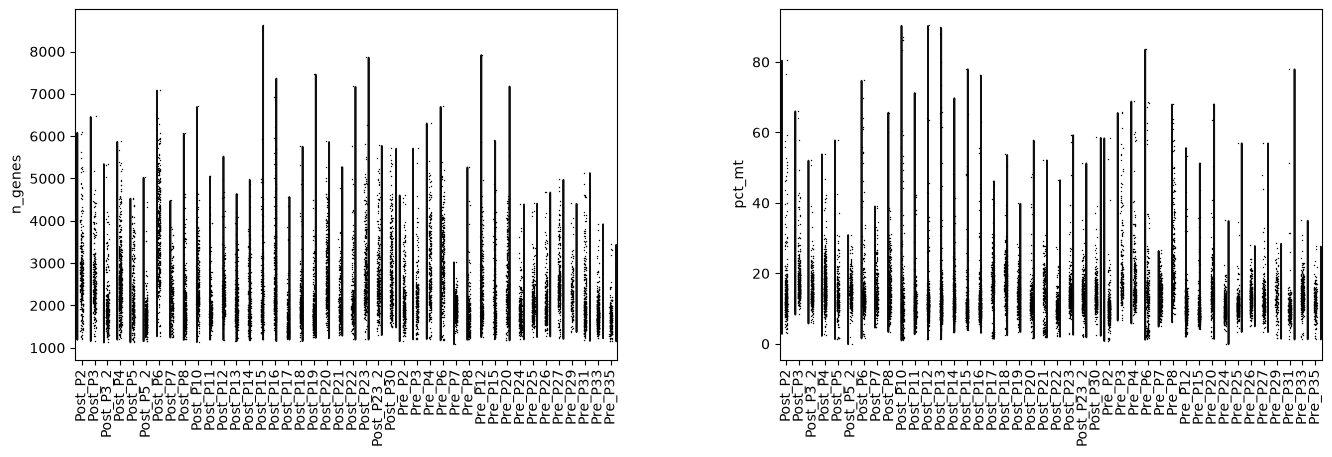

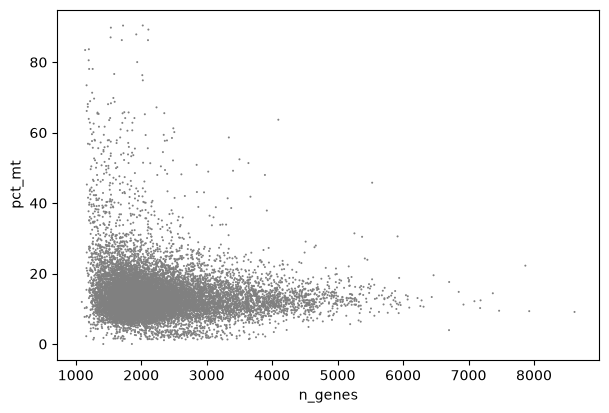

0.01    1266.0
0.05    1427.0
0.25    1763.0
0.50    2088.0
0.75    2599.0
0.95    3935.1
0.99    4979.0
Name: n_genes, dtype: float64
sample
Post_P17     1518.0
Pre_P35      1643.0
Post_P5_2    1683.0
Pre_P8       1718.0
Pre_P33      1751.0
Post_P19     1766.0
Pre_P24      1787.0
Post_P8      1801.0
Name: n_genes, dtype: float64
sample
Pre_P29     163
Post_P21    213
Post_P7     231
Pre_P35     238
Pre_P3      245
Post_P22    260
Pre_P8      267
Post_P17    281
dtype: int64


In [20]:
sc.pl.violin(adata, ["n_genes", "pct_mt"], groupby="sample", rotation=90, multi_panel=True)
sc.pl.scatter(adata, x="n_genes", y="pct_mt")

q = adata.obs
print(q["n_genes"].quantile([0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]))
print(q.groupby("sample")["n_genes"].median().sort_values().head(8))   # weakest samples
print(q.groupby("sample").size().sort_values().head(8))                # smallest samples

In [21]:
q = adata.obs
print(q["pct_mt"].quantile([0.5, 0.75, 0.9, 0.95, 0.99]))              # tail of the MT distribution
print(q.groupby("sample")["pct_mt"].median().sort_values().tail(8))    # samples with the highest MT

0.50    12.683290
0.75    16.024360
0.90    20.595700
0.95    24.842369
0.99    45.992921
Name: pct_mt, dtype: float64
sample
Pre_P4      14.869023
Post_P8     14.958539
Post_P4     15.485242
Post_P3     16.957374
Post_P17    17.078435
Pre_P3      17.507096
Post_P18    17.942701
Pre_P8      20.262294
Name: pct_mt, dtype: float64


In [22]:
q = adata.obs
genes_cut = [1100, 1300, 1500]    # the matrix floor is ~1100, so lower values remove nothing
mt_cut    = [20, 25, 30, 40]
tab = pd.DataFrame(
    {f"mt>{m}%": [((q["n_genes"] < g) | (q["pct_mt"] > m)).sum() for g in genes_cut]
     for m in mt_cut},
    index=[f"genes<{g}" for g in genes_cut])
print(tab)

            mt>20%  mt>25%  mt>30%  mt>40%
genes<1100    1592     700     405     211
genes<1300    1699     835     556     385
genes<1500    2365    1601    1375    1242


In [23]:
# Data-driven reference: median + 3 robust SDs of the MT percentage
mt = adata.obs["pct_mt"]
mad = (mt - mt.median()).abs().median()
print("median + 3*MAD threshold:", round(mt.median() + 3 * 1.4826 * mad, 1))

# Fraction of each sample's cells that a candidate threshold would remove
CAND_GENES, CAND_MT = 1100, 25    # candidate thresholds (change and re-run)
flag = (adata.obs["n_genes"] < CAND_GENES) | (adata.obs["pct_mt"] > CAND_MT)
per_sample = flag.groupby(adata.obs["sample"]).agg(["sum", "mean"])
per_sample.columns = ["n_removed", "frac_removed"]
print(per_sample.sort_values("frac_removed", ascending=False).head(10).round(3))
print("overall removed:", int(flag.sum()), f"({flag.mean():.1%})")

median + 3*MAD threshold: 25.9
          n_removed  frac_removed
sample                           
Pre_P8           88         0.330
Pre_P3           58         0.237
Pre_P4           33         0.106
Post_P3          37         0.103
Post_P7          22         0.095
Post_P17         26         0.093
Post_P2          33         0.087
Post_P8          35         0.086
Post_P18         30         0.084
Pre_P6           21         0.073
overall removed: 700 (4.9%)


In [24]:
MIN_GENES = 1100   # no effect (matrix floor ~1093); recorded for the report
MAX_MT    = 25     # tail of the MT distribution; matches median + 3*MAD = 25.9

n0 = adata.n_obs
ok = (adata.obs["n_genes"] >= MIN_GENES) & (adata.obs["pct_mt"] <= MAX_MT)
adata = adata[ok].copy()
sc.pp.filter_genes(adata, min_cells=10)   # drop genes detected in fewer than 10 cells

print("cells before:", n0, "| after:", adata.n_obs, "| genes:", adata.n_vars)
print(adata.obs["patient"].value_counts().tail(5))
print(adata.obs.drop_duplicates("sample")["timepoint"].value_counts())
print(adata.obs.groupby("response")["patient"].nunique())

cells before: 14340 | after: 13640 | genes: 34931
patient
P22    257
P17    255
P35    236
P21    201
P29    160
Name: count, dtype: int64
timepoint
Post    25
Pre     17
Name: count, dtype: int64
response
Non-responder    19
Responder        11
Name: patient, dtype: int64


In [25]:
adata.write_h5ad(DATA / "GSE120575_qc.h5ad")

In [26]:
# Group totals before QC (from the enrichment table of cell 10-b)
pre_qc = pd.Series({("Post", "Non-responder"): 6766, ("Post", "Responder"): 2212,
                    ("Pre", "Non-responder"): 2892, ("Pre", "Responder"): 2470})

post_qc = adata.obs.groupby(["timepoint", "response"], observed=True).size()
bal = pd.DataFrame({"before": pre_qc, "after": post_qc})
bal["removed"]      = bal["before"] - bal["after"]
bal["frac_removed"] = (bal["removed"] / bal["before"]).round(3)
print(bal)

print(adata.obs["sample"].value_counts()[["Pre_P8", "Pre_P3"]])   # expected ~179 and ~187
print(adata.obs.drop_duplicates("patient").set_index("patient").loc[["P8", "P3"], "response"])

                    before  after  removed  frac_removed
Post Non-responder    6766   6471      295         0.044
     Responder        2212   2075      137         0.062
Pre  Non-responder    2892   2760      132         0.046
     Responder        2470   2334      136         0.055
sample
Pre_P8    179
Pre_P3    187
Name: count, dtype: int64
patient
P8        Responder
P3    Non-responder
Name: response, dtype: category
Categories (2, str): ['Non-responder', 'Responder']


In [27]:
# The matrix is already log2(TPM+1), so NO further log transform is applied.
# Record the base so scanpy can invert it correctly (HVG selection, fold changes).
adata.uns["log1p"] = {"base": LOG_BASE}
print("X max:", adata.X.max(), "| log base:", LOG_BASE)

X max: 18.96 | log base: 2


C:\Users\hp\AppData\Roaming\uv\python\cpython-3.12-windows-x86_64-none\Lib\functools.py:912: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


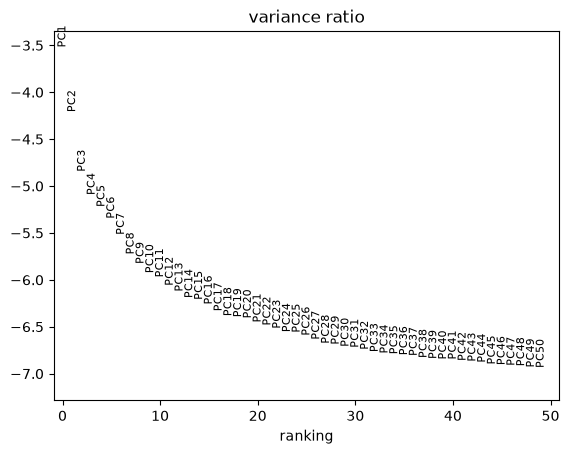

In [28]:
sc.pp.highly_variable_genes(adata, n_top_genes=3000, batch_key="patient")

# Scale a COPY (scaling changes values; adata.X must stay as real log-expression)
adata_hvg = adata[:, adata.var["highly_variable"]].copy()
sc.pp.scale(adata_hvg, max_value=10)
sc.tl.pca(adata_hvg, n_comps=50)
sc.pl.pca_variance_ratio(adata_hvg, n_pcs=50, log=True)

adata.obsm["X_pca"] = adata_hvg.obsm["X_pca"]
adata.uns["pca"]    = adata_hvg.uns["pca"]

f:\melanoma\melanoma-scrna-analysis\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


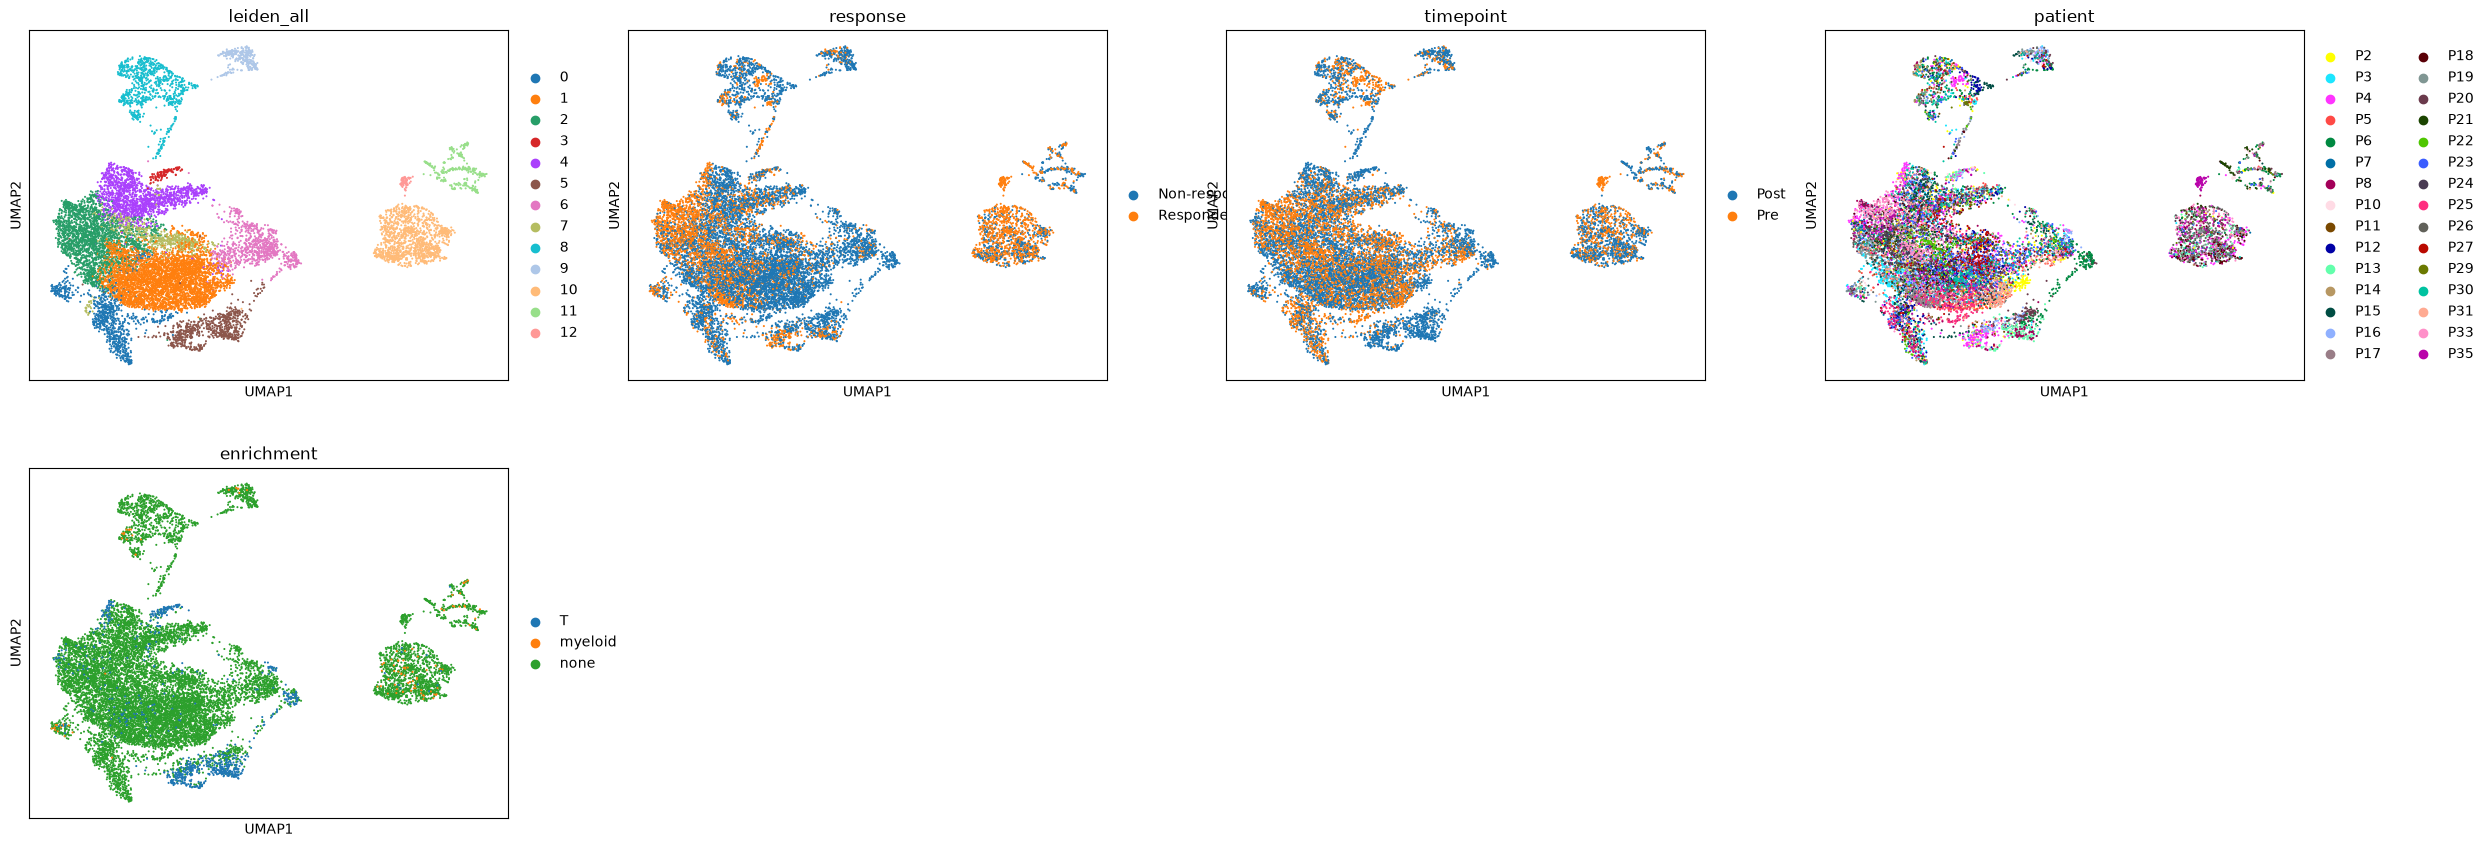

leiden_all
0      913
1     3894
2     2281
3      106
4     1545
5      727
6      843
7      580
8      843
9      278
10    1266
11     295
12      69
Name: count, dtype: int64


In [29]:
USE_HARMONY = False   # set True only if UMAP shows patient-driven islands within a cell type

if USE_HARMONY:       # requires: uv pip install harmonypy
    sc.external.pp.harmony_integrate(adata, key="patient")
    REP = "X_pca_harmony"
else:
    REP = "X_pca"

sc.pp.neighbors(adata, n_neighbors=15, n_pcs=30, use_rep=REP)
sc.tl.umap(adata)
sc.tl.leiden(adata, resolution=0.5, key_added="leiden_all",
             flavor="igraph", n_iterations=2, directed=False)

sc.pl.umap(adata, color=["leiden_all", "response", "timepoint", "patient", "enrichment"])
print(adata.obs["leiden_all"].value_counts().sort_index())

genes not in the matrix: []


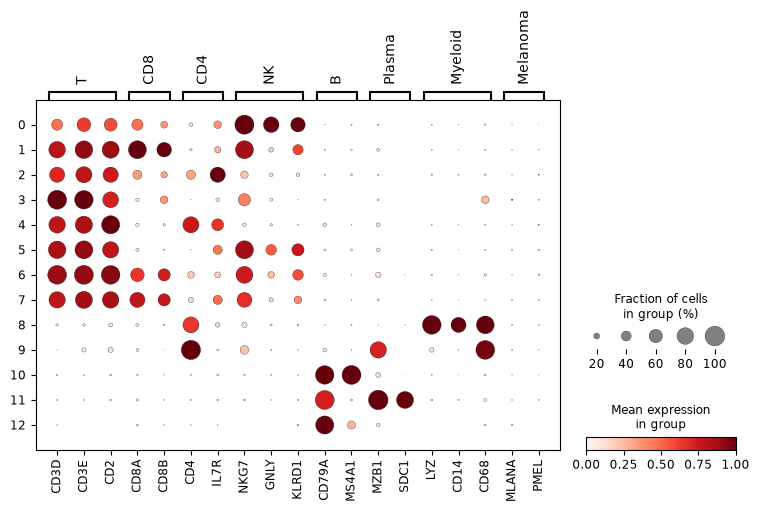

            CD3D  CD3E   CD2  frac_CD3D+  n_cells  n_patients
leiden_all                                                   
0           4.64  4.40  4.93        0.47      913          30
1           7.99  6.40  7.59        0.80     3894          30
2           6.92  5.54  6.38        0.71     2281          30
3           9.89  7.01  6.12        0.95      106          15
4           7.88  5.93  8.51        0.80     1545          30
5           8.45  6.41  6.80        0.86      727          26
6           8.91  6.37  7.94        0.94      843          27
7           7.89  6.15  7.31        0.78      580          30
8           0.45  0.35  0.72        0.07      843          27
9           0.04  0.60  1.08        0.01      278          24
10          0.16  0.09  0.15        0.03     1266          28
11          0.15  0.06  0.10        0.02      295          23
12          0.08  0.00  0.00        0.01       69           3


In [30]:
markers = {
    "T":        ["CD3D", "CD3E", "CD2"],
    "CD8":      ["CD8A", "CD8B"],
    "CD4":      ["CD4", "IL7R"],
    "NK":       ["NKG7", "GNLY", "KLRD1"],
    "B":        ["CD79A", "MS4A1"],
    "Plasma":   ["MZB1", "SDC1"],
    "Myeloid":  ["LYZ", "CD14", "CD68"],
    "Melanoma": ["MLANA", "PMEL"],
}
missing = [g for v in markers.values() for g in v if g not in adata.var_names]
print("genes not in the matrix:", missing)
markers = {k: [g for g in v if g in adata.var_names] for k, v in markers.items()}
sc.pl.dotplot(adata, markers, groupby="leiden_all", standard_scale="var")

t_genes = ["CD3D", "CD3E", "CD2"]
df = sc.get.obs_df(adata, keys=t_genes + ["leiden_all"])
summary = df.groupby("leiden_all", observed=True)[t_genes].mean().round(2)
summary["frac_CD3D+"] = (df["CD3D"] > 0).groupby(df["leiden_all"], observed=True).mean().round(2)
summary["n_cells"]    = df["leiden_all"].value_counts()
summary["n_patients"] = adata.obs.groupby("leiden_all", observed=True)["patient"].nunique()
print(summary)

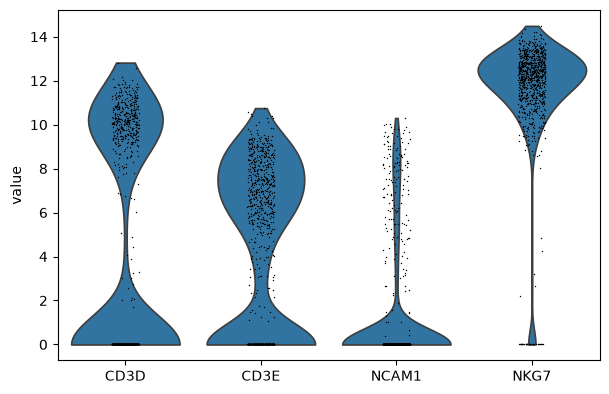

In [31]:
sc.pl.violin(adata[adata.obs["leiden_all"] == "0"], ["CD3D", "CD3E", "NCAM1", "NKG7"])

In [32]:
c0 = adata[adata.obs["leiden_all"] == "0"]
x = c0[:, ["CD3D", "CD3E"]].X
x = x.toarray() if hasattr(x, "toarray") else np.asarray(x)
is_t = (x[:, 0] > 0) & (x[:, 1] > 0)
print("cluster 0 cells:", len(is_t), "| CD3D+ and CD3E+:", int(is_t.sum()), f"({is_t.mean():.1%})")

cluster 0 cells: 913 | CD3D+ and CD3E+: 348 (38.1%)


In [33]:
tcl = ["1", "2", "3", "4", "5", "6", "7"]

# CD3D+ and CD3E+ cells inside cluster 0 (cluster 0 mixes T and NK)
x = adata[:, ["CD3D", "CD3E"]].X
x = x.toarray() if hasattr(x, "toarray") else np.asarray(x)
cd3_pos = (x[:, 0] > 0) & (x[:, 1] > 0)
in_c0 = (adata.obs["leiden_all"] == "0").to_numpy()

# Flag for the sensitivity analysis: T cells that came from cluster 0
adata.obs["from_c0"] = in_c0

keep = adata.obs["leiden_all"].isin(tcl).to_numpy() | (in_c0 & cd3_pos)
t = adata[keep].copy()
print(t.shape)
print(t.obs.drop_duplicates("patient")["response"].value_counts())
print("T cells from cluster 0:", int(t.obs["from_c0"].sum()))

cnt = t.obs.groupby(["patient", "timepoint"], observed=True).size()
print(cnt.sort_values().head(8))
print((cnt < 20).sum(), "patient-timepoints have fewer than 20 T cells, of", len(cnt))

(10324, 34931)
response
Non-responder    19
Responder        11
Name: count, dtype: int64
T cells from cluster 0: 348
patient  timepoint
P6       Pre           89
P35      Pre          108
P21      Post         113
P8       Pre          120
P26      Pre          124
P29      Pre          133
P3       Pre          137
P18      Post         156
dtype: int64
0 patient-timepoints have fewer than 20 T cells, of 39


TCR genes removed from HVGs: 114


C:\Users\hp\AppData\Roaming\uv\python\cpython-3.12-windows-x86_64-none\Lib\functools.py:912: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


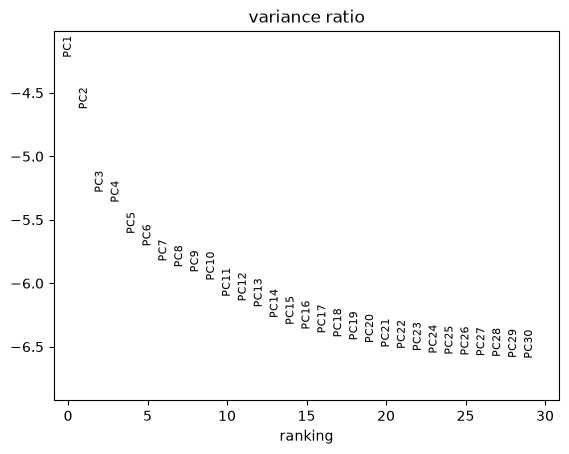

resolution 0.2 -> 5 clusters
resolution 0.4 -> 7 clusters
resolution 0.6 -> 11 clusters
resolution 0.8 -> 15 clusters


In [34]:
sc.pp.highly_variable_genes(t, n_top_genes=2000, batch_key="patient")

# Exclude TCR genes from HVGs: they encode the clonotype and would split clusters by clone
tcr = t.var_names.str.match(r"^TR[ABDG][VJC]")
t.var["highly_variable"] = t.var["highly_variable"] & ~tcr
print("TCR genes removed from HVGs:", int(tcr.sum()))

t_hvg = t[:, t.var["highly_variable"]].copy()
sc.pp.scale(t_hvg, max_value=10)
sc.tl.pca(t_hvg, n_comps=30)
sc.pl.pca_variance_ratio(t_hvg, n_pcs=30, log=True)
t.obsm["X_pca"] = t_hvg.obsm["X_pca"]
t.uns["pca"]    = t_hvg.uns["pca"]

sc.pp.neighbors(t, n_neighbors=15, n_pcs=20, use_rep="X_pca")
sc.tl.umap(t)
for r in [0.2, 0.4, 0.6, 0.8]:
    sc.tl.leiden(t, resolution=r, key_added=f"tsub_{r}",
                 flavor="igraph", n_iterations=2, directed=False)
    print("resolution", r, "->", t.obs[f"tsub_{r}"].nunique(), "clusters")

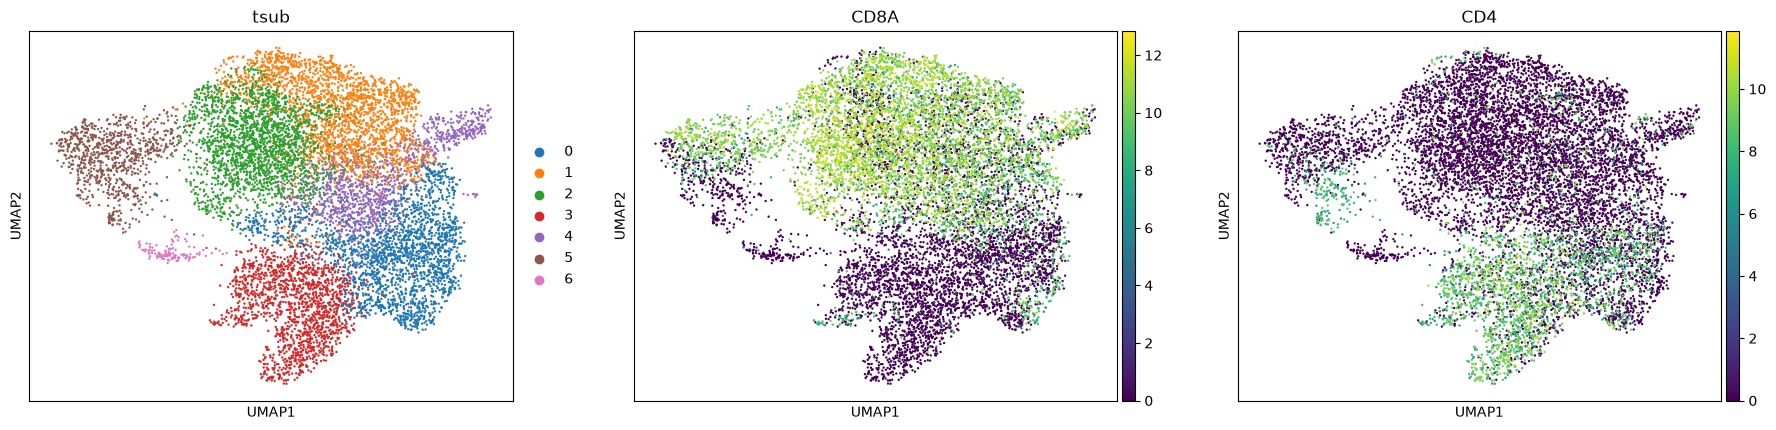

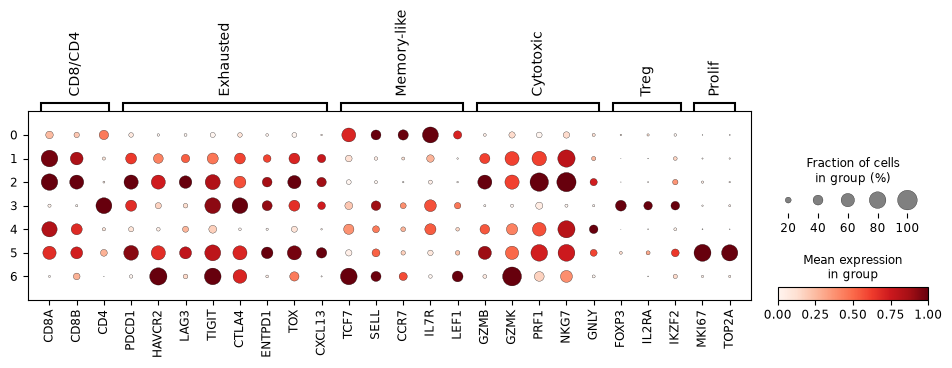

       group           names  logfoldchanges      pvals_adj
0          0            IL7R        4.717896  1.238567e-297
1          0           RPL13        0.804804  2.652429e-253
2          0           RPL10        0.653353  9.195595e-225
3          0            RPL3        0.898552  1.436744e-223
4          0          EEF1A1        0.545422  1.513153e-204
5          0            RPS6        0.721148  3.419860e-187
6          0           RPS12        0.919929  5.761496e-184
7          0            TCF7        3.164763  3.920764e-177
34931      1           CXCR4        2.641363   0.000000e+00
34932      1            CCL5        3.966155  9.446095e-211
34933      1         TNFAIP3        2.435734  7.487049e-174
34934      1         TSC22D3        2.253159  1.862626e-156
34935      1            CST7        2.552121  1.364954e-136
34936      1            CD8A        3.552694  1.569878e-135
34937      1           KLRK1        2.866022  1.585850e-127
34938      1           DUSP4        2.27

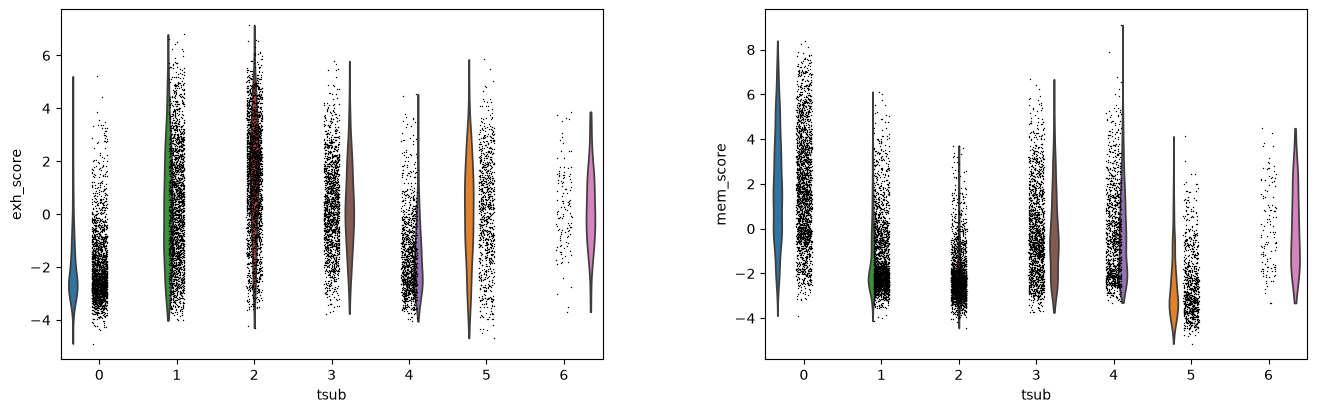

In [35]:
TSUB = "tsub_0.4"                # the resolution you chose
t.obs["tsub"] = t.obs[TSUB]

sc.pl.umap(t, color=["tsub", "CD8A", "CD4"])   # do NOT color by response before naming clusters

t_markers = {
    "CD8/CD4":     ["CD8A", "CD8B", "CD4"],
    "Exhausted":   ["PDCD1", "HAVCR2", "LAG3", "TIGIT", "CTLA4", "ENTPD1", "TOX", "CXCL13"],
    "Memory-like": ["TCF7", "SELL", "CCR7", "IL7R", "LEF1"],
    "Cytotoxic":   ["GZMB", "GZMK", "PRF1", "NKG7", "GNLY"],
    "Treg":        ["FOXP3", "IL2RA", "IKZF2"],
    "Prolif":      ["MKI67", "TOP2A"],
}
t_markers = {k: [g for g in v if g in t.var_names] for k, v in t_markers.items()}
sc.pl.dotplot(t, t_markers, groupby="tsub", standard_scale="var")

sc.tl.rank_genes_groups(t, "tsub", method="wilcoxon")
top = sc.get.rank_genes_groups_df(t, group=None)
print(top.groupby("group").head(8)[["group", "names", "logfoldchanges", "pvals_adj"]])

sc.tl.score_genes(t, ["PDCD1", "HAVCR2", "LAG3", "TIGIT", "CTLA4", "TOX"], score_name="exh_score")
sc.tl.score_genes(t, ["TCF7", "SELL", "CCR7", "IL7R", "LEF1"], score_name="mem_score")
sc.pl.violin(t, ["exh_score", "mem_score"], groupby="tsub")

In [36]:
# Number of patients with at least one cell in each T sub-cluster
print(pd.crosstab(t.obs["tsub"], t.obs["patient"]).gt(0).sum(axis=1).rename("n_patients"))

# Number of cells per T sub-cluster
print(t.obs["tsub"].value_counts().sort_index())

tsub
0    30
1    30
2    29
3    30
4    30
5    27
6    15
Name: n_patients, dtype: int64
tsub
0    2131
1    2213
2    2259
3    1589
4    1150
5     860
6     122
Name: count, dtype: int64


phenotype
Exhausted_CD8          2259
CD8_effector_memory    2213
Memory_like_CD4        2131
Treg                   1589
Memory_like_CD8        1150
Proliferating_CD8       860
Unassigned_small        122
Name: count, dtype: int64
phenotype
CD8_effector_memory    30
Exhausted_CD8          29
Memory_like_CD4        30
Memory_like_CD8        30
Proliferating_CD8      27
Treg                   30
Unassigned_small       15
dtype: int64


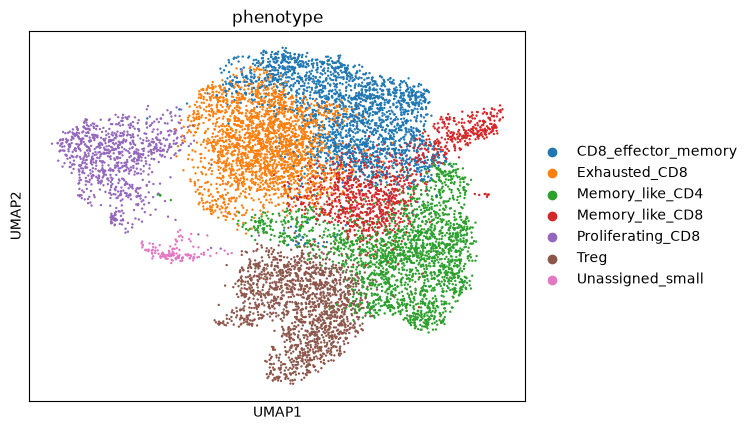

In [37]:
# Map each T sub-cluster (resolution 0.4) to a phenotype name, based on markers only
cluster_to_phenotype = {
    "0": "Memory_like_CD4",
    "1": "CD8_effector_memory",
    "2": "Exhausted_CD8",
    "3": "Treg",
    "4": "Memory_like_CD8",
    "5": "Proliferating_CD8",
    "6": "Unassigned_small",
}
t.obs["phenotype"] = t.obs["tsub"].astype(str).map(cluster_to_phenotype)
assert t.obs["phenotype"].notna().all(), "some cluster has no phenotype name"

# Cells per phenotype
print(t.obs["phenotype"].value_counts())

# Number of patients per phenotype
print(pd.crosstab(t.obs["phenotype"], t.obs["patient"]).gt(0).sum(axis=1))

# UMAP colored by phenotype only (not by response)
sc.pl.umap(t, color="phenotype")

  timepoint        phenotype  n_R  n_NR  median_R  median_NR     AUC  p_value     FDR
0       Pre    Exhausted_CD8    8     9    0.0785     0.1685  0.4028   0.5414  0.8542
1       Pre  Memory_like_CD8    8     9    0.0974     0.1059  0.5278   0.8884  0.8884
2      Post    Exhausted_CD8    6    16    0.0371     0.2585  0.2292   0.0587  0.2348
3      Post  Memory_like_CD8    6    16    0.0966     0.0765  0.5729   0.6407  0.8542


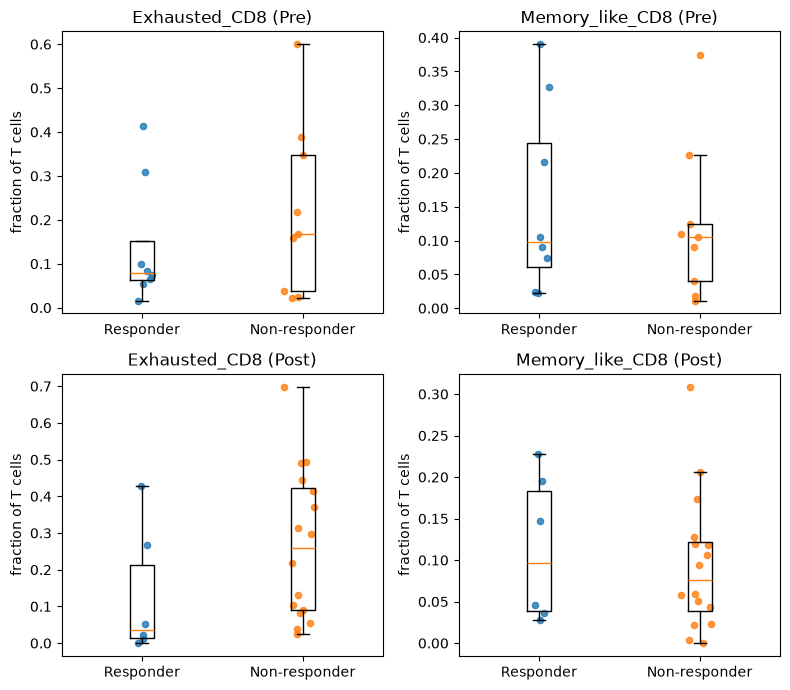

Exhausted_CD8 Fisher (cell level): 1.85449845963803e-53
Memory_like_CD8 Fisher (cell level): 9.679165665811674e-19


In [38]:
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.stats import mannwhitneyu, fisher_exact, false_discovery_control

# Folder for result tables and figures (created if it does not exist)
Path("../results").mkdir(exist_ok=True)

# Phenotypes to test: decided BEFORE looking at any p-value
MAIN  = ["Exhausted_CD8", "Memory_like_CD8"]
# Minimum number of T cells required per patient-timepoint
MIN_T = 20


def compare_props(obs, phenotypes=MAIN, min_t=MIN_T):
    # Count cells per patient, timepoint, response and phenotype
    # (cells of one patient and timepoint are pooled: patient = statistical unit)
    cnt = (obs.groupby(["patient", "timepoint", "response", "phenotype"], observed=True)
              .size().unstack("phenotype", fill_value=0))

    # Stop with a clear message if a phenotype name does not exist
    missing = [p for p in phenotypes if p not in cnt.columns]
    if missing:
        raise ValueError(f"phenotype(s) not found: {missing}")

    # Total T cells per patient-timepoint (all phenotypes), then drop small ones
    cnt["n_total"] = cnt.sum(axis=1)
    cnt = cnt[cnt["n_total"] >= min_t]

    # Convert counts to proportions of all T cells
    prop = cnt.drop(columns="n_total").div(cnt["n_total"], axis=0).reset_index()

    out = []
    for tp in ["Pre", "Post"]:
        d = prop[prop["timepoint"] == tp]
        for ph in phenotypes:
            a = d.loc[d["response"] == "Responder", ph]
            b = d.loc[d["response"] == "Non-responder", ph]
            # Skip a test if a group has fewer than 2 patients
            if len(a) < 2 or len(b) < 2:
                continue
            # Two-sided Mann-Whitney U test on patient-level proportions
            u, p = mannwhitneyu(a, b, alternative="two-sided")
            out.append(dict(timepoint=tp, phenotype=ph, n_R=len(a), n_NR=len(b),
                            median_R=a.median(), median_NR=b.median(),
                            AUC=u / (len(a) * len(b)), p_value=p))

    res = pd.DataFrame(out)
    if res.empty:
        raise ValueError("no test could be run (too few patients per group)")

    # Benjamini-Hochberg FDR across all tests in this table
    res["FDR"] = false_discovery_control(res["p_value"].to_numpy(), method="bh")
    return prop, res


# Safety check: only the two patient-level response labels should exist
assert set(t.obs["response"].unique()) == {"Responder", "Non-responder"}

# Run the main analysis and print the result table
prop, res = compare_props(t.obs)
print(res.round(4).to_string())


def boxplot_prop(prop, ph, tp, ax):
    # Boxplot + one dot per patient for one phenotype and one timepoint
    d = prop[prop["timepoint"] == tp]
    groups = ["Responder", "Non-responder"]
    data = [d.loc[d["response"] == g, ph].to_numpy() for g in groups]
    ax.boxplot(data, showfliers=False)
    rng = np.random.default_rng(0)          # fixed seed: same jitter every run
    for i, v in enumerate(data, 1):
        ax.scatter(rng.normal(i, 0.05, len(v)), v, s=20, alpha=0.8)
    ax.set_xticks([1, 2])
    ax.set_xticklabels(groups)
    ax.set_title(f"{ph} ({tp})")
    ax.set_ylabel("fraction of T cells")


# 2 x 2 figure: rows = Pre/Post, columns = the two main phenotypes
fig, axes = plt.subplots(2, 2, figsize=(8, 7))
for r, tp in enumerate(["Pre", "Post"]):
    for c, ph in enumerate(MAIN):
        boxplot_prop(prop, ph, tp, axes[r, c])
fig.tight_layout()
fig.savefig("../results/tcell_phenotype_proportions.png", dpi=150)
plt.show()

# Supplementary only: cell-level Fisher test (pseudoreplicated, p-values NOT valid)
for ph in MAIN:
    tab = pd.crosstab(t.obs["phenotype"] == ph, t.obs["response"])
    print(ph, "Fisher (cell level):", fisher_exact(tab)[1])

In [39]:
# Sensitivity 1: does the result depend on the enriched cells (all in Post)?
obs_ns = t.obs[~t.obs["is_enriched"].astype(bool)]
print("T cells before:", len(t.obs), "| after dropping enriched:", len(obs_ns))
prop_ns, res_ns = compare_props(obs_ns)
print(res_ns.round(4).to_string())

T cells before: 10324 | after dropping enriched: 9534
  timepoint        phenotype  n_R  n_NR  median_R  median_NR     AUC  p_value     FDR
0       Pre    Exhausted_CD8    8     9    0.0785     0.1685  0.4028   0.5414  0.8884
1       Pre  Memory_like_CD8    8     9    0.0974     0.1059  0.5278   0.8884  0.8884
2      Post    Exhausted_CD8    6    16    0.0399     0.2199  0.2083   0.0402  0.1607
3      Post  Memory_like_CD8    6    16    0.0730     0.0761  0.5625   0.6931  0.8884


In [40]:
# Sensitivity 2: does the result depend on T cells recovered from cluster 0?
obs_no_c0 = t.obs[~t.obs["from_c0"].astype(bool)]
print("T cells before:", len(t.obs), "| after dropping cluster-0 cells:", len(obs_no_c0))
prop_nc0, res_nc0 = compare_props(obs_no_c0)
print(res_nc0.round(4).to_string())
res_nc0.to_csv("../results/phenotype_tests_no_cluster0.tsv", sep="\t", index=False)

T cells before: 10324 | after dropping cluster-0 cells: 9976
  timepoint        phenotype  n_R  n_NR  median_R  median_NR     AUC  p_value     FDR
0       Pre    Exhausted_CD8    8     9    0.0816     0.1685  0.3889   0.4807  0.5802
1       Pre  Memory_like_CD8    8     9    0.0879     0.0588  0.6528   0.3213  0.5802
2      Post    Exhausted_CD8    6    16    0.0361     0.2562  0.2292   0.0587  0.2348
3      Post  Memory_like_CD8    6    16    0.0870     0.0431  0.5833   0.5802  0.5802


In [41]:
# Sensitivity table, paper-style (sample-level unit). All settings fixed BEFORE seeing any p-value.
# NOT the main analysis: samples from the same patient are not independent (pseudoreplication).
from scipy.stats import mannwhitneyu, false_discovery_control

CD8_PHENOS = ["CD8_effector_memory", "Exhausted_CD8",
              "Memory_like_CD8", "Proliferating_CD8"]
TEST   = ["Exhausted_CD8", "Memory_like_CD8"]
MIN_N  = 20    # minimum cells (in the denominator set) per sample

# (setting name, phenotypes in the denominator or None for all T cells, timepoints)
SETTINGS = [
    ("1_CD8_PrePost",  CD8_PHENOS, ["Pre", "Post"]),
    ("2_CD8_Pre",      CD8_PHENOS, ["Pre"]),
    ("3_CD8_Post",     CD8_PHENOS, ["Post"]),
    ("4_allT_PrePost", None,       ["Pre", "Post"]),
]

rows = []
for name, phenos, tps in SETTINGS:
    o = t.obs[t.obs["timepoint"].isin(tps)]
    if phenos is not None:
        o = o[o["phenotype"].isin(phenos)]

    # Cells per sample and phenotype (sample = lesion, with its own response label)
    cnt = (o.groupby(["sample", "response_sample", "phenotype"], observed=True)
             .size().unstack("phenotype", fill_value=0))
    cnt["n_total"] = cnt.sum(axis=1)          # denominator = all cells in this set
    cnt = cnt[cnt["n_total"] >= MIN_N]
    prop_s = cnt[TEST].div(cnt["n_total"], axis=0).reset_index()

    for ph in TEST:
        a = prop_s.loc[prop_s["response_sample"] == "Responder", ph]
        b = prop_s.loc[prop_s["response_sample"] == "Non-responder", ph]
        if len(a) < 2 or len(b) < 2:
            continue
        u, p = mannwhitneyu(a, b, alternative="two-sided")
        rows.append(dict(setting=name, phenotype=ph, n_R=len(a), n_NR=len(b),
                         median_R=a.median(), median_NR=b.median(),
                         AUC=u / (len(a) * len(b)), p_value=p))

res_sens = pd.DataFrame(rows)

# One FDR correction across ALL rows of the table
res_sens["FDR"] = false_discovery_control(res_sens["p_value"].to_numpy(), method="bh")
print(res_sens.round(4).to_string())
res_sens.to_csv("../results/paper_style_sensitivity_table.tsv", sep="\t", index=False)

          setting        phenotype  n_R  n_NR  median_R  median_NR     AUC  p_value     FDR
0   1_CD8_PrePost    Exhausted_CD8   14    28    0.1572     0.2578  0.2959   0.0339  0.0920
1   1_CD8_PrePost  Memory_like_CD8   14    28    0.1610     0.1262  0.6250   0.1956  0.3673
2       2_CD8_Pre    Exhausted_CD8    7    10    0.1707     0.2453  0.4143   0.6009  0.7903
3       2_CD8_Pre  Memory_like_CD8    7    10    0.1739     0.1498  0.6857   0.2295  0.3673
4      3_CD8_Post    Exhausted_CD8    7    18    0.0748     0.3822  0.2222   0.0345  0.0920
5      3_CD8_Post  Memory_like_CD8    7    18    0.1286     0.1188  0.5397   0.7903  0.7903
6  4_allT_PrePost    Exhausted_CD8   14    28    0.0598     0.2181  0.2411   0.0070  0.0563
7  4_allT_PrePost  Memory_like_CD8   14    28    0.0821     0.0939  0.5357   0.7187  0.7903


In [42]:
# Two-state CD8 analysis (paper-inspired definition). All choices fixed BEFORE seeing any result.
# Rule: a CD8 cell is "memory-like" if mem_score > exh_score, otherwise "exhausted-like".
# Test: fraction of memory-like cells among all CD8 cells, Mann-Whitney two-sided, FDR threshold 0.05.
from scipy.stats import mannwhitneyu, false_discovery_control

CD8_PHENOS = ["CD8_effector_memory", "Exhausted_CD8",
              "Memory_like_CD8", "Proliferating_CD8"]
MIN_N = 20   # minimum CD8 cells per unit (patient-timepoint or sample)

# Keep only CD8 cells and label each cell with the two-state rule
cd8 = t.obs[t.obs["phenotype"].isin(CD8_PHENOS)].copy()
cd8["mem_like"] = (cd8["mem_score"] > cd8["exh_score"]).astype(float)

# Sanity check (does not use response): how the rule agrees with the 4 phenotypes
print(cd8.groupby("phenotype", observed=True)["mem_like"].mean().round(3))


def unit_fractions(df, unit_cols):
    # Fraction of memory-like cells and number of CD8 cells per unit
    g = (df.groupby(unit_cols, observed=True)
           .agg(frac_mem=("mem_like", "mean"), n_cd8=("mem_like", "size"))
           .reset_index())
    return g[g["n_cd8"] >= MIN_N]


def run_test(g, resp_col, name):
    # Compare Responder vs Non-responder units with Mann-Whitney
    a = g.loc[g[resp_col] == "Responder", "frac_mem"]
    b = g.loc[g[resp_col] == "Non-responder", "frac_mem"]
    u, p = mannwhitneyu(a, b, alternative="two-sided")
    return dict(setting=name, n_R=len(a), n_NR=len(b),
                median_R=a.median(), median_NR=b.median(),
                AUC=u / (len(a) * len(b)), p_value=p)


rows = []

# A and B: patient-level (main unit), Pre and Post separately
for tp, name in [("Pre", "A_patient_Pre"), ("Post", "B_patient_Post")]:
    g = unit_fractions(cd8[cd8["timepoint"] == tp], ["patient", "response"])
    rows.append(run_test(g, "response", name))

# C: sample-level (paper-style unit), Pre and Post pooled. Pseudoreplication: samples of one patient are not independent
g = unit_fractions(cd8, ["sample", "response_sample"])
rows.append(run_test(g, "response_sample", "C_sample_PrePost"))

res_two = pd.DataFrame(rows)

# One FDR correction across the 3 tests
res_two["FDR"] = false_discovery_control(res_two["p_value"].to_numpy(), method="bh")
print(res_two.round(4).to_string())
res_two.to_csv("../results/two_state_cd8_tests.tsv", sep="\t", index=False)

phenotype
CD8_effector_memory    0.312
Exhausted_CD8          0.114
Memory_like_CD8        0.720
Proliferating_CD8      0.172
Name: mem_like, dtype: float64
            setting  n_R  n_NR  median_R  median_NR     AUC  p_value     FDR
0     A_patient_Pre    8     9    0.4783     0.2176  0.7917   0.0464  0.0464
1    B_patient_Post    6    16    0.5884     0.2488  0.8438   0.0133  0.0200
2  C_sample_PrePost   14    28    0.5643     0.2152  0.7883   0.0027  0.0081


In [43]:
# Sensitivity for the two-state analysis (fixed in advance): drop enriched cells, drop cluster-0 cells
rows = []
for label, mask in [("no_enriched", ~cd8["is_enriched"].astype(bool)),
                    ("no_cluster0", ~cd8["from_c0"].astype(bool))]:
    d = cd8[mask]
    for tp, name in [("Pre", "A_patient_Pre"), ("Post", "B_patient_Post")]:
        g = unit_fractions(d[d["timepoint"] == tp], ["patient", "response"])
        r = run_test(g, "response", name); r["variant"] = label; rows.append(r)
    g = unit_fractions(d, ["sample", "response_sample"])
    r = run_test(g, "response_sample", "C_sample_PrePost"); r["variant"] = label; rows.append(r)

res_sens2 = pd.DataFrame(rows)
# One FDR correction across all 6 tests
res_sens2["FDR"] = false_discovery_control(res_sens2["p_value"].to_numpy(), method="bh")
print(res_sens2.round(4).to_string())
res_sens2.to_csv("../results/two_state_cd8_sensitivity.tsv", sep="\t", index=False)

            setting  n_R  n_NR  median_R  median_NR     AUC  p_value      variant     FDR
0     A_patient_Pre    8     9    0.4783     0.2176  0.7917   0.0464  no_enriched  0.0464
1    B_patient_Post    6    16    0.5612     0.2940  0.8646   0.0080  no_enriched  0.0160
2  C_sample_PrePost   14    28    0.5612     0.2285  0.7959   0.0021  no_enriched  0.0074
3     A_patient_Pre    8     9    0.4620     0.1844  0.7917   0.0464  no_cluster0  0.0464
4    B_patient_Post    6    16    0.5761     0.2485  0.8281   0.0223  no_cluster0  0.0334
5  C_sample_PrePost   14    28    0.5338     0.1953  0.7908   0.0025  no_cluster0  0.0074
